# Transfer learning and fine-tuning

This notebook covers the required deep-learning model: a **pretrained Persian encoder, fine-tuned** on the
Digikala reviews for both targets at once. It follows the report the project asks for:

1. which checkpoint, and why;
2. its size, tokenizer and maximum length;
3. the training settings;
4. the training and validation curves, the checkpoint kept and the stopping rule;
5. signs of overfitting or instability;
6. Macro F1 and the per-class scores of both heads, on validation and test;
7. whether fine-tuning improved on the TF-IDF baseline.

It ends with every model tried in the project side by side, the final system, and two of the optional extensions
(the exact rate and a frozen encoder).

Nothing is trained here. Every number is read from `reports/`; the test scores come from the single reading of the
test set (`reports/final_evaluation.json`). The tables marked "from `scripts/summarize_results.py`" are the same
tables as in `reports/results_summary.md`.

In [1]:
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown

from digikala_reviews import plotting
from digikala_reviews.config import FIGURES_DIR, FINAL_TRANSFORMER_RESULT, PROJECT_ROOT, REPORTS_DIR
from digikala_reviews.tfidf import HEADS

sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
import summarize_results  # noqa: E402

plotting.apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if float(v).is_integer() else f"{v:,.4f}")
HEAD_TITLES = {"recommendation": "Recommendation", "rating_band": "Rating band"}


def load_report(name):
    return json.loads((REPORTS_DIR / name).read_text(encoding="utf-8"))


def summary_table(section):
    # one section of reports/results_summary.md, without its title
    lines = section()
    return Markdown("\n".join(line for line in lines if not line.startswith("## ")))


fabert = load_report(FINAL_TRANSFORMER_RESULT)
required = load_report("required_metrics.json")["heads"]
final = load_report("final_evaluation.json")["heads"]
seeds = load_report("full_seeds.json")["heads"]
tokenizers = load_report("tokenizers/compare.json")["models"]
pilot_fabert = load_report("transformer_pilot_whole/sbunlp__fabert.json")
hub = load_report("fabert_files.json")

## 1. The checkpoint

Six public encoders were compared, in three steps fixed before any of them was run
(`reports/transformer_model_choice.md`):

1. their tokenizers on 50,000 training reviews;
2. one epoch of fine-tuning on 100,000 reviews, the same for all, three seeds for the strongest;
3. the two best on 500,000 reviews, three seeds each.

The rule, written before step 3: a lead smaller than the spread between seeds is a tie, and a tie goes to the faster
model.

In [2]:
summary_table(summarize_results.transformer_pilot_whole)


| Model | Training reviews | Seeds | Recommendation | Rating band | Mean | Seeds range | Minutes |
|---|---|---|---|---|---|---|---|
| PartAI/TookaBERT-Large | 100,000 | 3 | 0.7119 | 0.6792 | 0.6956 | 0.6951 to 0.6960 | 2.2 |
| sbunlp/fabert | 100,000 | 3 | 0.7102 | 0.6757 | 0.6929 | 0.6925 to 0.6936 | 0.9 |
| jhu-clsp/mmBERT-base | 100,000 | 1 | 0.7053 | 0.6719 | 0.6886 | 0.6886 to 0.6886 | 1.8 |
| PartAI/TookaBERT-Base | 100,000 | 3 | 0.7013 | 0.6699 | 0.6856 | 0.6841 to 0.6868 | 0.9 |
| FacebookAI/xlm-roberta-base | 100,000 | 1 | 0.7004 | 0.6693 | 0.6848 | 0.6848 to 0.6848 | 1.2 |
| HooshvareLab/bert-fa-zwnj-base | 100,000 | 1 | 0.6881 | 0.6579 | 0.6730 | 0.6730 to 0.6730 | 0.9 |
| PartAI/TookaBERT-Large | 500,000 | 3 | 0.7243 | 0.6872 | 0.7058 | 0.7050 to 0.7062 | 11.0 |
| sbunlp/fabert | 500,000 | 3 | 0.7231 | 0.6861 | 0.7046 | 0.7043 to 0.7049 | 4.3 |

Summary made with 085b8f7 · local

TookaBERT-Large minus FaBERT, both on 500,000 reviews, same reviews per seed:

| Seed | Recommendation [95%] | Rating band [95%] |
|---|---|---|
| 2026 | +0.0001 [-0.0008, +0.0009] | +0.0013 [+0.0007, +0.0020] |
| 2027 | +0.0017 [+0.0008, +0.0026] | +0.0013 [+0.0006, +0.0020] |
| 2028 | +0.0019 [+0.0011, +0.0028] | +0.0008 [+0.0002, +0.0015] |

Lead of TookaBERT-Large +0.00117, spread between seeds 0.00124: tie, chosen sbunlp__fabert (a lead smaller than the spread between seeds is a tie; a tie goes to the faster model). Made with 42ec92d.


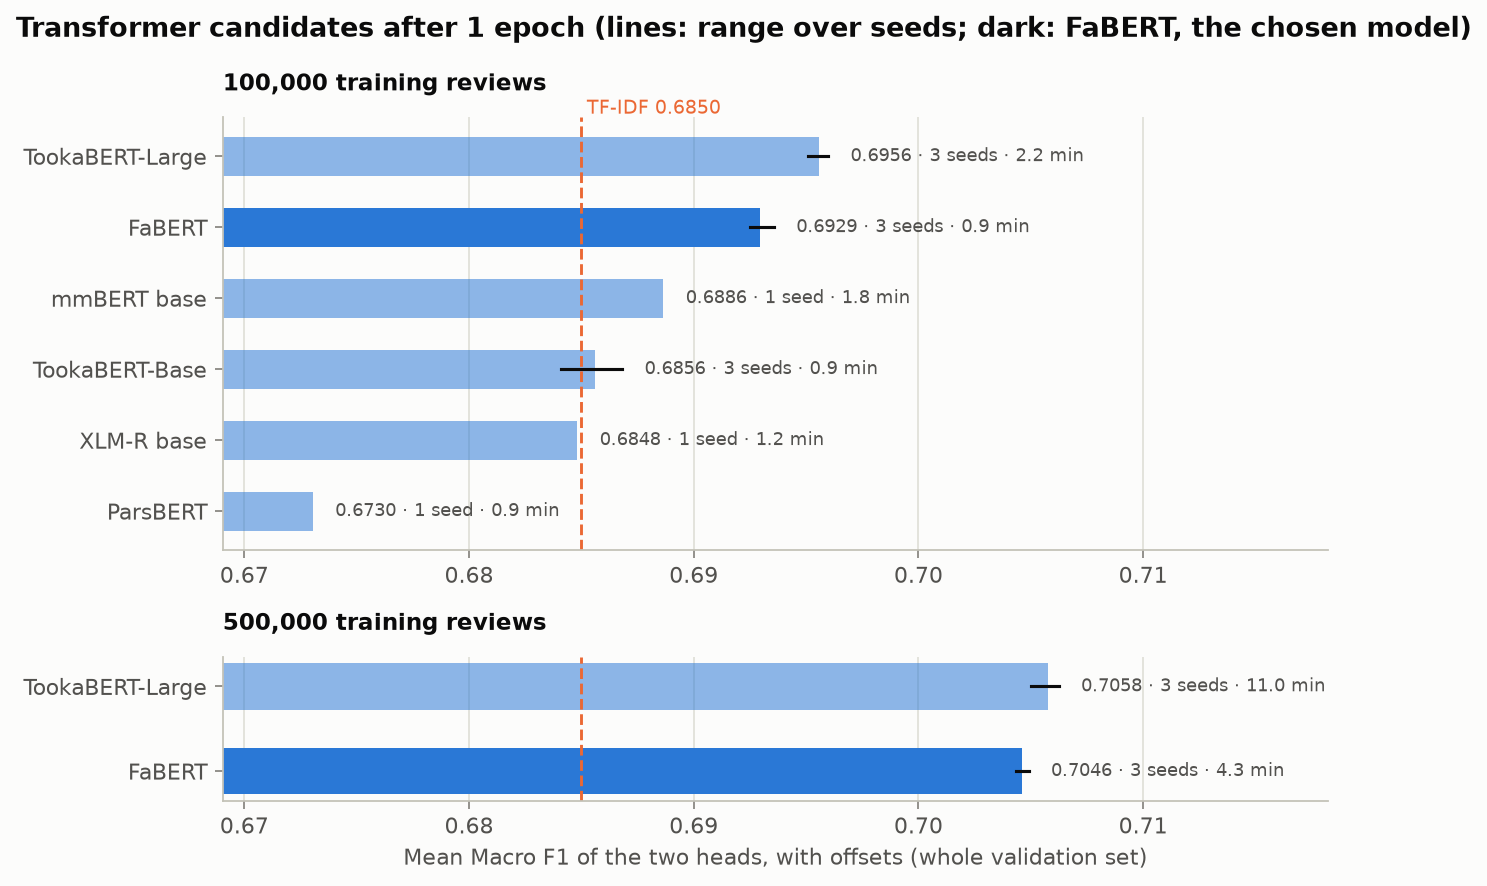

In [3]:
Image(FIGURES_DIR / "results_model_comparison.png")

TookaBERT-Large led FaBERT by 0.12 point on 500,000 reviews, less than the spread between seeds (also 0.12 point),
so by the rule it is a tie. FaBERT is 2.6 times faster and needs a third of the memory: **FaBERT
(`sbunlp/fabert`) was chosen** (decision D51). It is a BERT-base encoder pretrained on Persian blogs (Masumi et al.,
"FaBERT: Pre-training BERT on Persian Blogs", W-NUT 2025).

The model card and the files of its hub repository state **no licence** (checked on 2026-11-08). The weights are
public and are used here for study and research, with the paper cited; the tokenizer files are saved locally by
`scripts/save_fabert_files.py` and are not put in the repository.

## 2. Size, tokenizer and maximum length

In [4]:
fab = tokenizers["sbunlp/fabert"]
pd.Series(
    {
        "checkpoint": "sbunlp/fabert",
        "hub commit": hub["hub_commit"][:12],
        "parameters, total": f"{pilot_fabert['parameters']:,}",
        "parameters, trainable": f"{pilot_fabert['parameters']:,} (the whole encoder is fine-tuned)",
        "tokenizer": "WordPiece, FaBERT's own",
        "vocabulary": f"{fab['vocabulary_size']:,}",
        "maximum length": f"{fabert['fingerprint']['settings']['max_length']} tokens",
        "tokens per review (median, 99th percentile)": f"{fab['tokens_per_review']['median']:.0f}, "
        f"{fab['tokens_per_review']['p99']:.0f}",
        "reviews longer than 128 tokens": f"{fab['longer_than']['128']:.2%}",
        "unknown tokens": f"{fab['unknown_token_share']:.2%} of all tokens",
    },
    name="FaBERT",
).to_frame()

,FaBERT
checkpoint,sbunlp/fabert
hub commit,4cad2850ab81
"parameters, total","124,445,958"
"parameters, trainable","124,445,958 (the whole encoder is fine-tuned)"
tokenizer,"WordPiece, FaBERT's own"
vocabulary,"50,000"
maximum length,128 tokens
"tokens per review (median, 99th percentile)","7, 72"
reviews longer than 128 tokens,0.21%
unknown tokens,0.07% of all tokens


The model is the encoder with one linear head per task (recommendation, rating band) on the first token's output.
The two heads are 2 × 2,307 of the parameters.

**Why 128 tokens.** Section 5 of notebook 01 found that reviews are short (median 6 words). With FaBERT's tokenizer
the median review is 7 tokens and the 99th percentile 72 (50,000 training reviews, seed 2026); only 0.21% are longer
than 128, and they are cut at the end. A longer limit would cost memory and time on every batch for almost no
reviews.

## 3. Training settings

In [5]:
s = fabert["fingerprint"]["settings"]
pd.Series(
    {
        "training reviews": f"{fabert['training_reviews']:,} (all of train_supervised)",
        "loss": "sum of the two heads' cross-entropies; a missing label is ignored for its head only",
        "optimizer": f"AdamW, weight decay {s['weight_decay']} (none on biases and norms)",
        "learning rate": f"{s['learning_rate']:g}, the same for the encoder and the heads",
        "schedule": f"{s['warmup_share']:.0%} linear warmup, then linear decay to 0",
        "batch": f"{s['batch_size']}, no gradient accumulation",
        "dropout": s["dropout"],
        "epochs": f"{s['max_epochs']} ({fabert['steps_per_epoch']:,} steps each)",
        "checks": f"{s['checks_per_epoch']} per epoch, on {s['selection_rows']:,} fixed validation reviews",
        "precision": "bfloat16 on the GPU, gradient norm clipped at 1.0",
        "seed": s["seed"],
    },
    name="setting",
).to_frame()

,setting
training reviews,"3,552,498 (all of train_supervised)"
loss,sum of the two heads' cross-entropies; a missing label is ignored for its head only
optimizer,"AdamW, weight decay 0.01 (none on biases and norms)"
learning rate,"3e-05, the same for the encoder and the heads"
schedule,"6% linear warmup, then linear decay to 0"
batch,"64, no gradient accumulation"
dropout,0.1000
epochs,"4 (55,508 steps each)"
checks,"4 per epoch, on 50,000 fixed validation reviews"
precision,"bfloat16 on the GPU, gradient norm clipped at 1.0"


**One learning rate for the encoder and the heads.** The project suggests a smaller rate for the encoder than for the
heads when that helps. Here the heads are small (2,307 parameters each) and start from zero, and the whole model
trains for hundreds of thousands of steps. Three alternatives were tried on the 500,000-review pilot with three seeds
each (`reports/learning_rate_plan.md`): 2e-5 and 5e-5 for everything, and a layer-wise decay of 0.9 that gives lower
encoder layers a lower rate. None beat one rate of 3e-5 (decision D57; table in section 8).

## 4. Training and validation curves, and the checkpoint kept

The model was trained for all 4 epochs (the learning rate reaches 0 at the end). Four times per epoch it was scored
on a fixed sample of 50,000 validation reviews: the mean Macro F1 of the two heads with offsets (each half of the
sample scored with offsets tuned on the other half, by product). **The best check is kept**; there is no early
stopping in the kept run. A first run that stopped after two checks without improvement kept epoch 1.25 and was
0.27 and 0.14 point worse on the whole validation set (`reports/transformer_model_choice.md`).

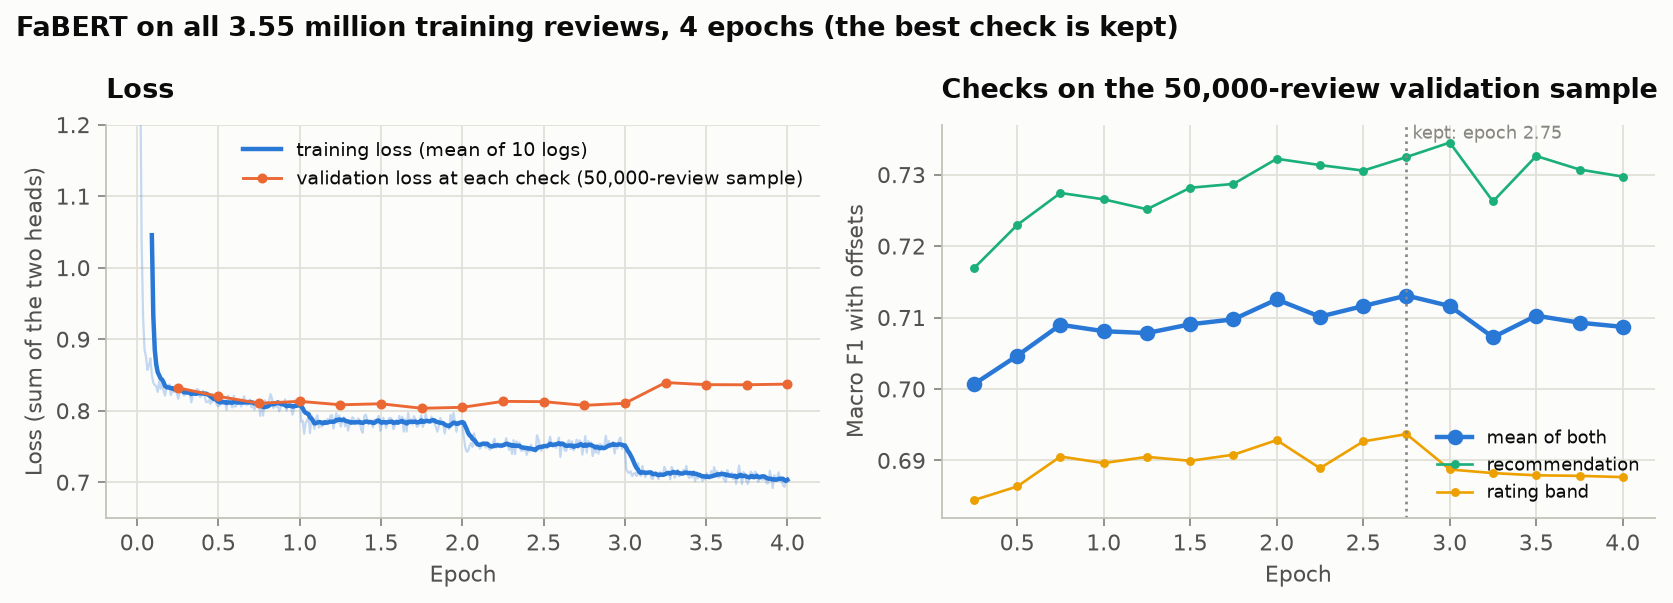

In [6]:
Image(FIGURES_DIR / "results_training_curve.png")

In [7]:
summary_table(summarize_results.transformer_final)


Checks on the 50,000-review validation sample, with offsets:

| Epoch | Step | Mean | Recommendation | Rating band | Validation loss |  |
|---|---|---|---|---|---|---|
| 0.25 | 13,877 | 0.7007 | 0.7169 | 0.6844 | 0.8321 | kept |
| 0.5 | 27,754 | 0.7047 | 0.7230 | 0.6864 | 0.8201 | kept |
| 0.75 | 41,631 | 0.7090 | 0.7274 | 0.6905 | 0.8104 | kept |
| 1.0 | 55,508 | 0.7081 | 0.7265 | 0.6896 | 0.8131 |  |
| 1.25 | 69,385 | 0.7078 | 0.7252 | 0.6905 | 0.8083 |  |
| 1.5 | 83,262 | 0.7091 | 0.7282 | 0.6899 | 0.8097 | kept |
| 1.75 | 97,139 | 0.7098 | 0.7287 | 0.6908 | 0.8034 | kept |
| 2.0 | 111,016 | 0.7125 | 0.7322 | 0.6928 | 0.8048 | kept |
| 2.25 | 124,893 | 0.7101 | 0.7313 | 0.6889 | 0.8131 |  |
| 2.5 | 138,770 | 0.7116 | 0.7306 | 0.6927 | 0.8127 |  |
| 2.75 | 152,647 | 0.7131 | 0.7325 | 0.6937 | 0.8075 | kept |
| 3.0 | 166,524 | 0.7116 | 0.7345 | 0.6887 | 0.8104 |  |
| 3.25 | 180,401 | 0.7072 | 0.7262 | 0.6882 | 0.8394 |  |
| 3.5 | 194,278 | 0.7103 | 0.7326 | 0.6879 | 0.8365 |  |
| 3.75 | 208,155 | 0.7093 | 0.7307 | 0.6878 | 0.8363 |  |
| 4.0 | 222,032 | 0.7087 | 0.7297 | 0.6877 | 0.8372 |  |

Trained with 287977c · molab GPU. Whole validation set (compared with 59a3ce9 · local):

| Head | FaBERT without offsets | FaBERT with offsets | TF-IDF with offsets | Difference [95%] |
|---|---|---|---|---|
| recommendation | 0.7253 | 0.7324 | 0.7017 | +0.0308 [+0.0295, +0.0321] |
| rating_band | 0.6799 | 0.6922 | 0.6683 | +0.0239 [+0.0229, +0.0249] |

| Head | FaBERT validation loss | TF-IDF validation loss |
|---|---|---|
| recommendation | 0.3121 | 0.5004 |
| rating_band | 0.4925 | 0.5220 |

FaBERT loss of both heads: training 0.7505 (logged steps before the kept one), validation 0.8046.

Kept run (best check at epoch 2.75) against the first run, stopped early (best check at epoch 1.25), both with offsets on the whole validation set (made with 82ab4df):

| Head | Kept run | First run | Difference [95%] | Verdict |
|---|---|---|---|---|
| recommendation | 0.7324 | 0.7298 | +0.0027 [+0.0017, +0.0036] | better |
| rating_band | 0.6922 | 0.6908 | +0.0014 [+0.0006, +0.0022] | better |


## 5. Overfitting and instability

- **Overfitting.** The validation loss is lowest near epoch 1.75 to 2.75 (0.803 to 0.808) and rises clearly after
  epoch 3 (0.839 at 3.25), while the training loss keeps falling, with a step down at the start of every epoch,
  when the model sees the same reviews again: from epoch 3 it fits the training reviews more than it learns. Macro
  F1 holds up longer than the loss, and the best check (epoch 2.75) comes before the rise. Keeping the best check,
  not the last one, is what protects the result.
- **Instability.** The same run trained again with two other seeds (`reports/full_seeds_plan.md`):

In [8]:
summary_table(summarize_results.full_seeds)


Made with c5b243f. The official model is the seed 2026 run.

| Model | Head | Seed 2026 | Seed 2027 | Seed 2028 | Spread |
|---|---|---|---|---|---|
| FaBERT | recommendation | 0.7324 | 0.7317 | 0.7312 | 0.0012 |
| BiLSTM, every epoch | recommendation | 0.7195 | 0.7192 | 0.7182 | 0.0013 |
| FaBERT | rating_band | 0.6922 | 0.6929 | 0.6927 | 0.0007 |
| BiLSTM, every epoch | rating_band | 0.6838 | 0.6842 | 0.6811 | 0.0031 |

D58 (FaBERT + TF-IDF minus FaBERT) with each FaBERT seed:

| Head | Seed 2026 | Seed 2027 | Seed 2028 |
|---|---|---|---|
| recommendation | +0.0020 [+0.0014, +0.0026] | +0.0022 [+0.0015, +0.0029] | +0.0025 [+0.0018, +0.0032] |
| rating_band | +0.0013 [+0.0009, +0.0018] | +0.0004 [+0.0001, +0.0007] | +0.0014 [+0.0010, +0.0018] |


The three FaBERT runs differ by 0.12 point (recommendation) and 0.07 point (rating band) of Macro F1, and the gain
of the final system over FaBERT holds with every seed. The official model is the seed 2026 run, chosen before the
other seeds were trained (decision D68), not the best seed.

## 6. Results: Macro F1 and the per-class scores

FaBERT with offsets (tuned on validation as for TF-IDF), on the whole validation set and on the test set.

In [9]:
rows = []
for head in HEADS:
    for part, scores in [
        ("validation", required[head]["fabert"]),
        ("test", final[head]["models"]["fabert"]["with_offsets"]),
    ]:
        row = {
            "head": head,
            "set": part,
            "accuracy": scores["accuracy"],
            "Macro F1": scores["macro_f1"],
            "Macro precision": scores["macro_precision"],
            "Macro recall": scores["macro_recall"],
            "balanced accuracy": scores["balanced_accuracy"],
        }
        if head == "rating_band":
            row["ordinal distance"] = scores["ordinal_distance_error"]["mean_distance"]
            row["off by two"] = scores["ordinal_distance_error"]["share_off_by_two"]
        rows.append(row)
pd.DataFrame(rows).fillna("")

/tmp/ipykernel_4190/1260416694.py:20: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.DataFrame(rows).fillna("")


,head,set,accuracy,Macro F1,Macro precision,Macro recall,balanced accuracy,ordinal distance,off by two
0,recommendation,validation,0.8736,0.7324,0.7346,0.7320,0.7320,,
1,recommendation,test,0.8732,0.7346,0.7338,0.7374,0.7374,,
2,rating_band,validation,0.7945,0.6922,0.7046,0.6813,0.6813,0.2176,0.0121
3,rating_band,test,0.7941,0.6918,0.7040,0.6810,0.6810,0.2181,0.0122


In [10]:
per_class = []
for head in HEADS:
    for part, scores in [
        ("validation", required[head]["fabert"]),
        ("test", final[head]["models"]["fabert"]["with_offsets"]),
    ]:
        for label, c in scores["per_class"].items():
            per_class.append(
                {
                    "head": head,
                    "class": label,
                    "set": part,
                    "precision": c["precision"],
                    "recall": c["recall"],
                    "F1": c["f1"],
                }
            )
pd.DataFrame(per_class).pivot_table(
    index=["head", "class"], columns="set", values=["precision", "recall", "F1"], sort=False
)

precision            recall                F1  \
set                            validation   test validation   test validation   
head           class                                                            
recommendation recommended         0.9479 0.9498     0.9404 0.9373     0.9441   
               not_recommended     0.7735 0.7694     0.7159 0.7236     0.7436   
               no_idea             0.4826 0.4822     0.5399 0.5513     0.5096   
rating_band    low                 0.7503 0.7496     0.6756 0.6748     0.7110   
               medium              0.4859 0.4850     0.4716 0.4720     0.4786   
               high                0.8775 0.8775     0.8966 0.8961     0.8870   

                                       
set                              test  
head           class                   
recommendation recommended     0.9435  
               not_recommended 0.7458  
               no_idea         0.5145  
rating_band    low             0.7102  
               medium          0.4784  
               high            0.8867

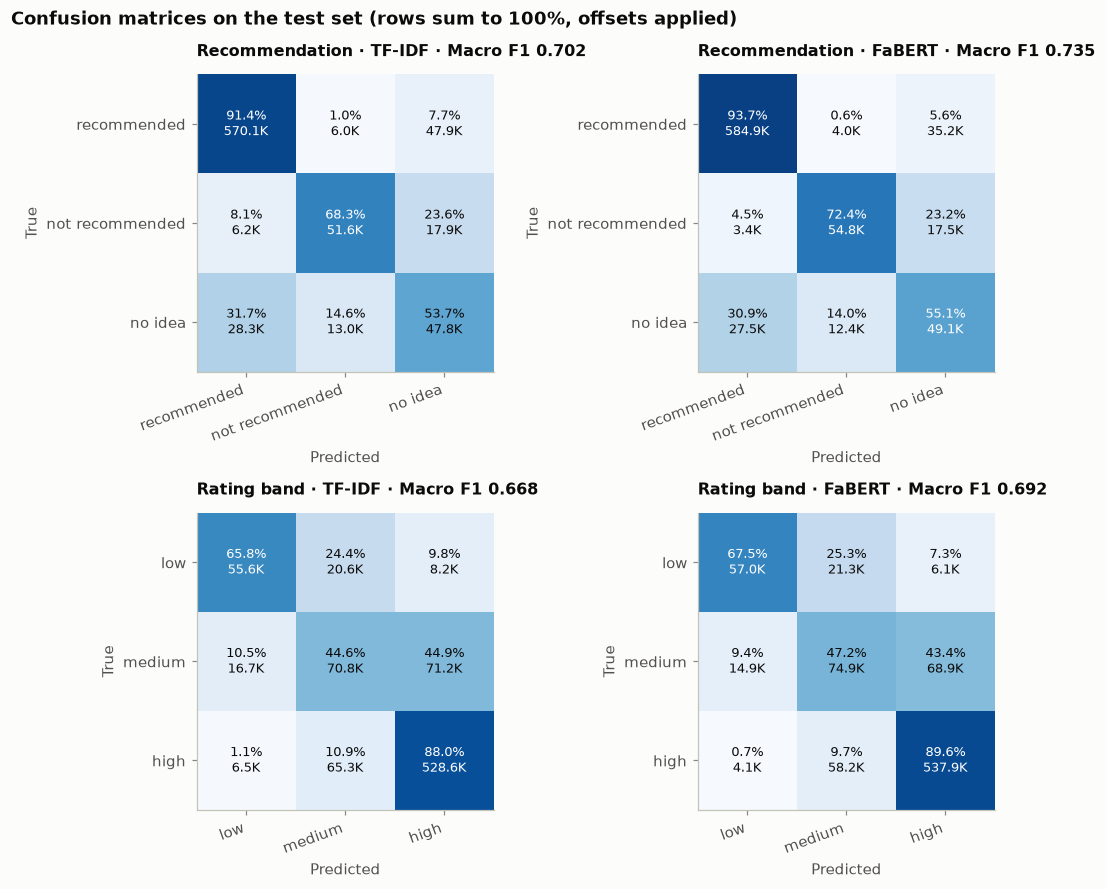

In [11]:
def draw_confusion(ax, scores, title):
    labels = scores["confusion_matrix"]["labels"]
    counts = np.array(scores["confusion_matrix"]["rows_are_true_class"], dtype=float)
    shares = counts / counts.sum(axis=1, keepdims=True) * 100
    ax.imshow(shares, cmap="Blues", vmin=0, vmax=100)
    ax.grid(False)
    for i in range(len(labels)):
        for j in range(len(labels)):
            color = "white" if shares[i, j] > 55 else plotting.INK
            ax.text(
                j,
                i,
                f"{shares[i, j]:.1f}%\n{plotting.compact(counts[i, j])}",
                ha="center",
                va="center",
                fontsize=8.5,
                color=color,
            )
    names = [label.replace("_", " ") for label in labels]
    ax.set_xticks(range(len(labels)), names, rotation=20, ha="right")
    ax.set_yticks(range(len(labels)), names)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title, fontsize=10.5)


fig, axes = plt.subplots(2, 2, figsize=(9.5, 8.2))
for row, head in enumerate(HEADS):
    for col, name in enumerate(["tfidf", "fabert"]):
        scores = final[head]["models"][name]["with_offsets"]
        model = "TF-IDF" if name == "tfidf" else "FaBERT"
        title = f"{HEAD_TITLES[head]} · {model} · Macro F1 {scores['macro_f1']:.3f}"
        draw_confusion(axes[row][col], scores, title)
fig.suptitle(
    "Confusion matrices on the test set (rows sum to 100%, offsets applied)",
    x=0.01,
    ha="left",
    fontsize=12,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

## 7. Did fine-tuning improve the result?

Yes, clearly, on both heads and every class. FaBERT against TF-IDF on the test set, with a 95% interval that draws
whole products (1,000 rounds):

In [12]:
rows = []
for head in HEADS:
    d = final[head]["differences"]["fabert minus tfidf"]
    low, high = d["macro_f1_interval_95_products"]
    row = {
        "head": head,
        "TF-IDF": final[head]["models"]["tfidf"]["with_offsets"]["macro_f1"],
        "FaBERT": final[head]["models"]["fabert"]["with_offsets"]["macro_f1"],
        "difference (points)": 100 * d["change"]["macro_f1"],
        "95% interval (points)": f"[{100 * low:+.2f}, {100 * high:+.2f}]",
    }
    for label in HEADS[head]["labels"]:
        row[f"F1 change: {label}"] = 100 * d["change"][f"{label} f1"]
    rows.append(row)
pd.DataFrame(rows).set_index("head").T.fillna("")

head,recommendation,rating_band
TF-IDF,0.7021,0.6684
FaBERT,0.7346,0.6918
difference (points),3.2473,2.3405
95% interval (points),"[+3.12, +3.39]","[+2.24, +2.45]"
F1 change: recommended,1.5363,
F1 change: not_recommended,3.9709,
F1 change: no_idea,4.2346,
F1 change: low,,2.8987
F1 change: medium,,2.9375
F1 change: high,,1.1853


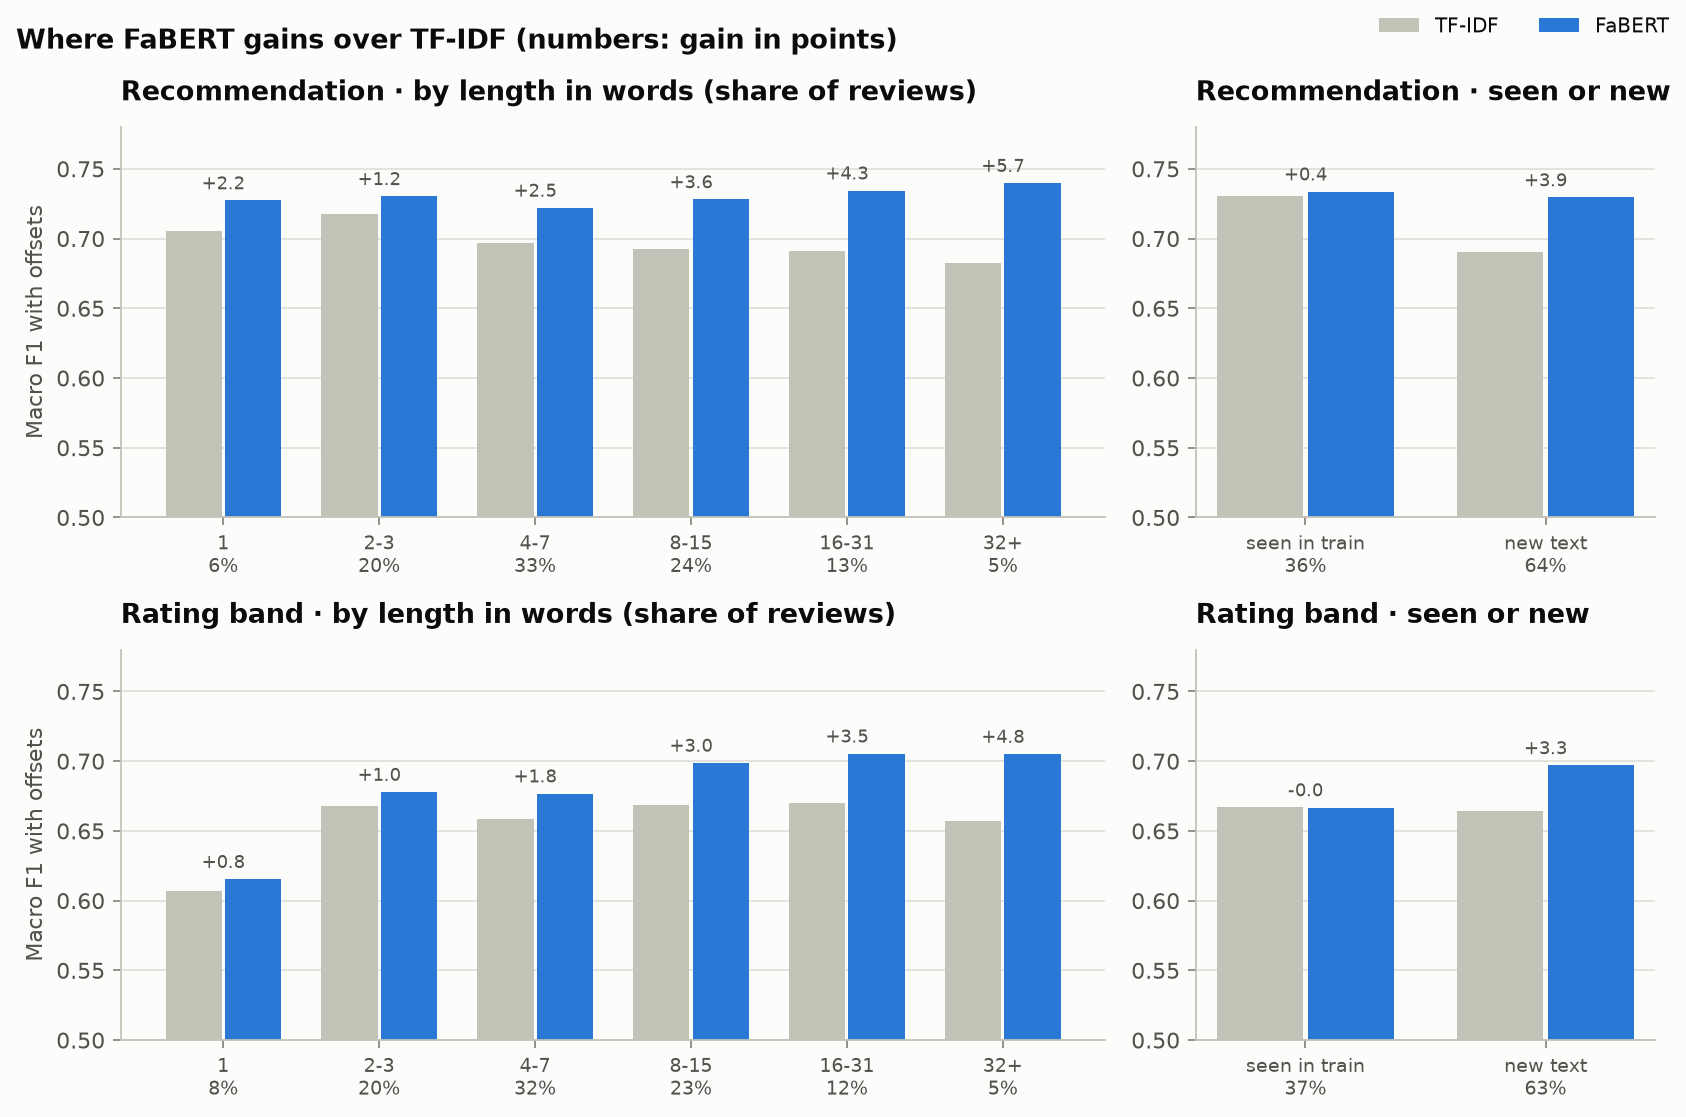

In [13]:
Image(FIGURES_DIR / "results_where_it_helps.png")

Where the gain comes from (validation, `scripts/plot_results.py`): FaBERT gains most on **longer reviews** and on
**texts not seen in training**. On very short texts, and on texts that also appear in the training reviews, both
models already do about as well as the labels allow (`reports/text_ceiling_plan.md`): the same text often comes
with different labels, so no model reading only the text can be right on all of them.

## 8. Every model tried, side by side

All models and training changes tried in the project, on the **validation set** (Macro F1 with offsets, whole
validation set). Only the TF-IDF baseline, FaBERT, the final system and the semi-supervised model were scored on the
test set; the others were compared on validation only and are not candidates any more.

In [14]:
macro = {head: seeds[head]["macro_f1"] for head in HEADS}
stacking = load_report("stacking.json")["heads"]
chooser = load_report("chooser.json")["heads"]
student = load_report("semi_supervised/student.json")["last_check"]["heads"]


def spread(key):
    return " / ".join(f"{100 * seeds[h][key]['spread']:.2f}" for h in HEADS)


models = [
    (
        "TF-IDF + logistic regression",
        {h: macro[h]["tfidf"] for h in HEADS},
        "",
        "the baseline; part of the final system",
    ),
    (
        "BiLSTM, trained from scratch",
        {h: macro[h]["bilstm_2026"] for h in HEADS},
        spread("bilstm_no_early_stop"),
        "between TF-IDF and FaBERT: pretraining is worth about 1 to 1.5 points",
    ),
    (
        "FaBERT, fine-tuned",
        {h: macro[h]["fabert_2026"] for h in HEADS},
        spread("fabert"),
        "the Transformer of the project (D51, D68)",
    ),
    (
        "FaBERT, pretrained further on the review texts",
        {h: macro[h]["adapted"] for h in HEADS},
        "",
        "+0.12 / +0.09 alone, but no gain inside the final system on recommendation (D65)",
    ),
    (
        "TookaBERT-Large, fine-tuned",
        {h: required[h]["large"]["macro_f1"] for h in HEADS},
        "",
        "ties FaBERT, three times the cost (D59)",
    ),
    (
        "FaBERT + TF-IDF, weighted mean (final system)",
        {h: macro[h]["fabert_2026 + tfidf"] for h in HEADS},
        "",
        "the system delivered (D58)",
    ),
    (
        "FaBERT + TF-IDF, stacking",
        {h: stacking[h]["stacking_against_blend"]["variant_macro_f1"] for h in HEADS},
        "",
        "below the weighted mean on recommendation (D60)",
    ),
    (
        "FaBERT + TF-IDF, learned chooser",
        {h: chooser[h]["versions"]["fabert_and_tfidf"]["chooser_macro_f1"] for h in HEADS},
        "",
        "below the weighted mean on recommendation (D63)",
    ),
    (
        "FaBERT + pseudo-labels (semi-supervised)",
        {h: student[h]["with_offsets"]["macro_f1"] for h in HEADS},
        "",
        "no measurable gain; notebook 04",
    ),
]
table = pd.DataFrame(
    [
        {
            "model": name,
            "recommendation": f1["recommendation"],
            "rating band": f1["rating_band"],
            "seed spread (points)": s,
            "decision": why,
        }
        for name, f1, s, why in models
    ]
)
table.style.format({"recommendation": "{:.4f}", "rating band": "{:.4f}"}).hide(axis="index")

model,recommendation,rating band,seed spread (points),decision
TF-IDF + logistic regression,0.7017,0.6683,,the baseline; part of the final system
"BiLSTM, trained from scratch",0.7195,0.6838,0.13 / 0.31,between TF-IDF and FaBERT: pretraining is worth about 1 to 1.5 points
"FaBERT, fine-tuned",0.7324,0.6922,0.12 / 0.07,"the Transformer of the project (D51, D68)"
"FaBERT, pretrained further on the review texts",0.7337,0.6931,,"+0.12 / +0.09 alone, but no gain inside the final system on recommendation (D65)"
"TookaBERT-Large, fine-tuned",0.7324,0.6938,,"ties FaBERT, three times the cost (D59)"
"FaBERT + TF-IDF, weighted mean (final system)",0.7344,0.6935,,the system delivered (D58)
"FaBERT + TF-IDF, stacking",0.7325,0.6939,,below the weighted mean on recommendation (D60)
"FaBERT + TF-IDF, learned chooser",0.7325,0.6940,,below the weighted mean on recommendation (D63)
FaBERT + pseudo-labels (semi-supervised),0.7310,0.6921,,no measurable gain; notebook 04


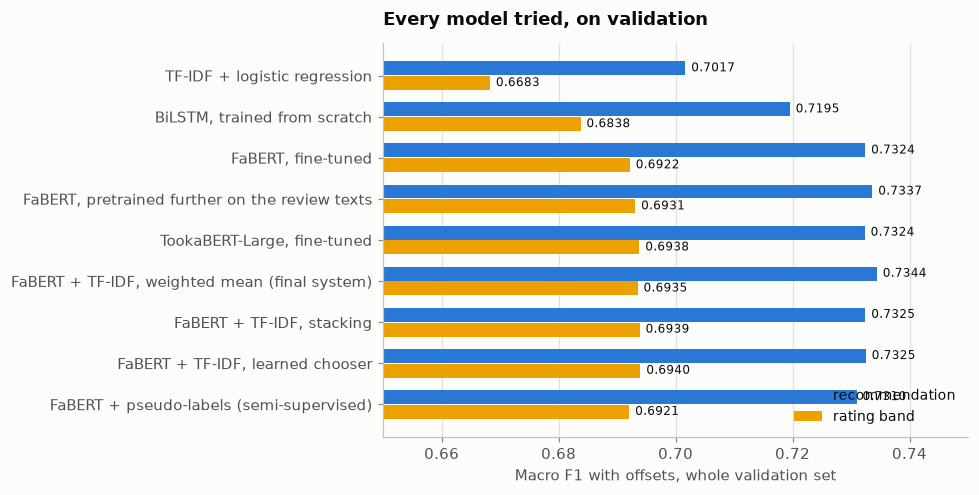

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(table))
ax.barh(y - 0.18, table["recommendation"], height=0.34, color=plotting.SERIES[0], label="recommendation")
ax.barh(y + 0.18, table["rating band"], height=0.34, color=plotting.SERIES[3], label="rating band")
for i, row in table.iterrows():
    ax.text(row["recommendation"] + 0.001, i - 0.18, f"{row['recommendation']:.4f}", va="center", fontsize=8)
    ax.text(row["rating band"] + 0.001, i + 0.18, f"{row['rating band']:.4f}", va="center", fontsize=8)
ax.set_yticks(y, table["model"])
ax.invert_yaxis()
ax.set_xlim(0.65, 0.75)
ax.set_xlabel("Macro F1 with offsets, whole validation set")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=9)
ax.set_title("Every model tried, on validation")
fig.tight_layout()
plt.show()

Changes to how FaBERT is trained were tested on a smaller pilot (500,000 reviews, one epoch, three seeds), where a
lead smaller than the spread between seeds counts as a tie. Only the further pretraining on the review texts won;
the others tied or lost (from `scripts/summarize_results.py`):

In [16]:
summary_table(summarize_results.training_variants)


Mean Macro F1 of the two heads over the seeds. A lead smaller than the spread between
seeds is a tie.

| Experiment | Variant | Score | Usual training | Lead | Spread | Verdict | Made with |
|---|---|---|---|---|---|---|---|
| Texts merged (reports/merged_texts_plan.md) | copies | 0.7043 | 0.7046 | -0.0002 | 0.0006 | tie | 73437c8 |
| Texts merged (reports/merged_texts_plan.md) | once | 0.7045 | 0.7046 | -0.0001 | 0.0006 | tie | 73437c8 |
| Hard reviews weighted up (reports/hard_examples_plan.md) | focal 0.5 | 0.7047 | 0.7051 | -0.0004 | 0.0006 | tie | 9622331 |
| Hard reviews weighted up (reports/hard_examples_plan.md) | focal 1 | 0.7046 | 0.7051 | -0.0005 | 0.0006 | tie | 9622331 |
| Hard reviews weighted up (reports/hard_examples_plan.md) | focal 2 | 0.7036 | 0.7051 | -0.0015 | 0.0012 | worse | 9622331 |
| Hard reviews weighted up (reports/hard_examples_plan.md) | class weights | 0.7021 | 0.7051 | -0.0029 | 0.0018 | worse | 9622331 |
| Difficulty used (reports/difficulty_plan.md) | leave out 5% | 0.7037 | 0.7051 | -0.0013 | 0.0006 | worse | f090d6c |
| Difficulty used (reports/difficulty_plan.md) | leave out 10% | 0.7026 | 0.7051 | -0.0025 | 0.0010 | worse | f090d6c |
| Difficulty used (reports/difficulty_plan.md) | curriculum | 0.1455 | 0.7051 | -0.5596 | 0.0192 | worse | f090d6c |
| Gradual curriculum (reports/difficulty_plan.md) | gradual curriculum | 0.7029 | 0.7051 | -0.0021 | 0.0009 | worse | bd13b11 |
| Learning rate (reports/learning_rate_plan.md) | learning rate 2e-5 | 0.7041 | 0.7051 | -0.0010 | 0.0008 | worse | 3f49121 |
| Learning rate (reports/learning_rate_plan.md) | learning rate 5e-5 | 0.7043 | 0.7051 | -0.0008 | 0.0009 | tie | 3f49121 |
| Learning rate (reports/learning_rate_plan.md) | layer decay 0.9 | 0.7032 | 0.7051 | -0.0019 | 0.0010 | worse | 3f49121 |
| Pseudo-labels (reports/semi_supervised_plan.md) | pseudo-labels 0.9 | 0.7047 | 0.7051 | -0.0003 | 0.0007 | tie | 2279ab7 |
| Domain-adapted FaBERT (reports/domain_adaptation_plan.md) | domain-adapted | 0.7072 | 0.7051 | +0.0021 | 0.0006 | better | be670fa |


## 9. The final system

The system delivered mixes the probabilities of FaBERT and TF-IDF (a weighted mean; the weight and the per-class
offsets are tuned on validation) and answers "uncertain" on its least confident 10% (the threshold also fixed on
validation; `reports/uncertain_plan.md`). On the test set:

In [17]:
rows = []
for head in HEADS:
    m = final[head]["models"]
    d = final[head]["differences"]["final system minus fabert"]
    low, high = d["macro_f1_interval_95_products"]
    u = m["final system"]["uncertain"]
    rows.append(
        {
            "head": head,
            "FaBERT Macro F1": m["fabert"]["with_offsets"]["macro_f1"],
            "final system Macro F1": m["final system"]["with_offsets"]["macro_f1"],
            "difference (points)": 100 * d["change"]["macro_f1"],
            "95% interval (points)": f"[{100 * low:+.2f}, {100 * high:+.2f}]",
            "validation difference (points)": 100
            * (m["final system"]["validation"]["macro_f1"] - m["fabert"]["validation"]["macro_f1"]),
            "answered 'uncertain'": f"{u['share']:.1%}",
            "accuracy on the answered reviews": u["answered_reviews"]["accuracy"],
        }
    )
pd.DataFrame(rows).set_index("head").T

head,recommendation,rating_band
FaBERT Macro F1,0.7346,0.6918
final system Macro F1,0.7349,0.6927
difference (points),0.0344,0.0874
95% interval (points),"[-0.02, +0.09]","[+0.05, +0.13]"
validation difference (points),0.1995,0.1334
answered 'uncertain',10.0%,10.0%
accuracy on the answered reviews,0.9189,0.8396


On the test set the mixture adds 0.09 point on the rating band (measurable) but only 0.03 point on recommendation,
with the interval across zero, where validation had shown +0.20. The final system was chosen on validation and is
not changed after reading the test set: on recommendation it is as good as FaBERT alone. Answering "uncertain" on
10% of the reviews raises accuracy to about 92% and 84%, as on validation.

## 10. Extensions: the exact rate and a frozen encoder

Two of the project's optional extensions, planned before they were trained (`reports/extensions_plan.md`) and reported
apart from the official result, which does not change. Their models were scored on the test set a second and last
time, together with the other extensions (D74, `reports/final_evaluation_extensions.json`).

**The exact rate.** FaBERT as the kept run, plus a third linear head that predicts the rate (standardized with the
training mean and spread); the three losses are added with weights 1, not tuned, and a rate of 0 is masked like a
missing label. The baseline is a ridge regression on the final TF-IDF features (`reports/extensions/rate_ridge.json`);
a constant, the training mean, gives R² 0. Predictions are clipped to [0, 5] and scored on the reviews with a valid
rate, above 0 and at most 5 (D75: one validation review has a rate of 2,500, which alone added 7.4 to every model's
MSE; the test set has none above 5).

In [18]:
extensions_validation = load_report("extensions_validation.json")
extensions_test = load_report("final_evaluation_extensions.json")
rows = []
for name, found in extensions_validation["rate"].items():
    for part, scores in [("validation", found["scores"]), ("test", extensions_test["rate"][name]["scores"])]:
        rows.append(
            {
                "model": name,
                "set": part,
                **{k: scores[k] for k in ("reviews", "mae", "rmse", "mse", "r2", "spearman")},
            }
        )
pd.DataFrame(rows).set_index(["model", "set"]).round(4) + 0.0  # no "-0.0000" for the constant

reviews    mae   rmse    mse     r2  \
model                    set                                               
FaBERT rate head         validation  843,458 0.5459 0.7395 0.5469 0.5837   
                         test        843,458 0.5467 0.7414 0.5497 0.5823   
TF-IDF ridge             validation  843,458 0.6088 0.7977 0.6364 0.5157   
                         test        843,458 0.6090 0.7988 0.6381 0.5151   
constant (training mean) validation  843,458 0.8765 1.1463 1.3139      0   
                         test        843,458 0.8772 1.1472 1.3161      0   

                                     spearman  
model                    set                   
FaBERT rate head         validation    0.6735  
                         test          0.6725  
TF-IDF ridge             validation    0.6214  
                         test          0.6213  
constant (training mean) validation       NaN  
                         test             NaN

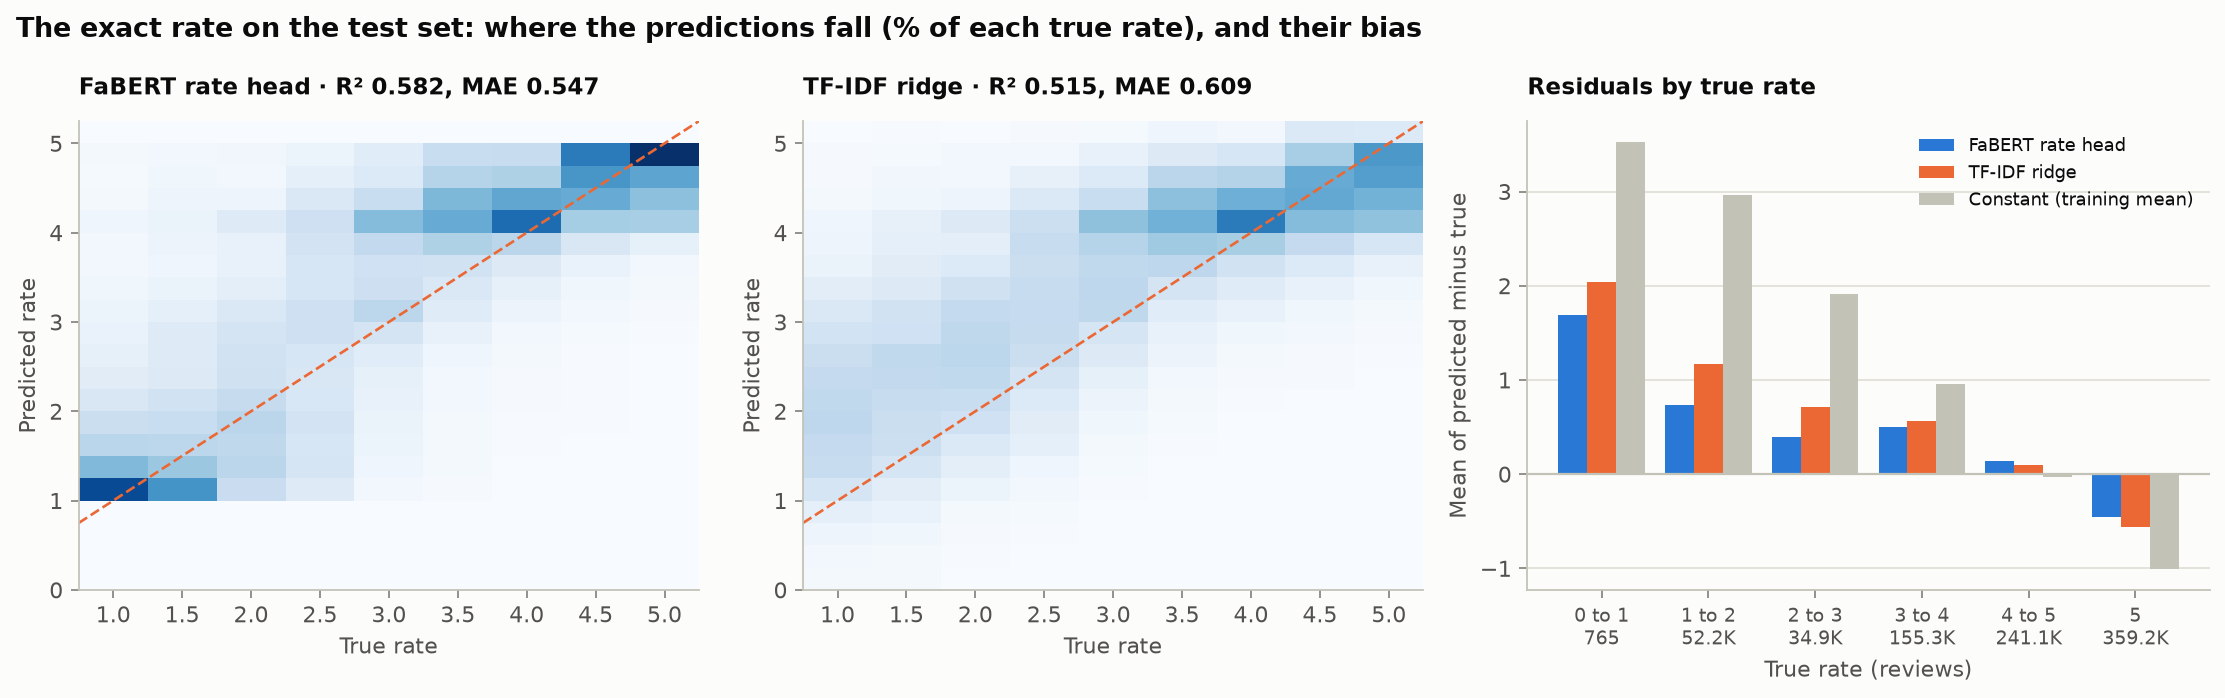

In [19]:
Image(FIGURES_DIR / "results_test_rate.png")

In [20]:
# the residuals on the test set: mean of predicted minus true, and the mean absolute error, by true rate
order = ["0 to 1", "1 to 2", "2 to 3", "3 to 4", "4 to 5", "5"]
rate = extensions_test["rate"]
table = pd.DataFrame(
    {"reviews": {b: rate["FaBERT rate head"]["residuals_by_true_rate"][b]["reviews"] for b in order}}
)
for name in rate:
    for k in ("mean_residual", "mae"):
        table[f"{name}: {k}"] = [rate[name]["residuals_by_true_rate"][b][k] for b in order]
table

,reviews,FaBERT rate head: mean_residual,FaBERT rate head: mae,TF-IDF ridge: mean_residual,TF-IDF ridge: mae,constant (training mean): mean_residual,constant (training mean): mae
0 to 1,765,1.6873,1.6873,2.0412,2.0551,3.5221,3.5221
1 to 2,52200,0.7386,0.7527,1.1662,1.2235,2.9661,2.9661
2 to 3,34875,0.3990,0.8160,0.7166,0.9087,1.9175,1.9175
3 to 4,155321,0.5031,0.8460,0.5677,0.7911,0.9575,0.9575
4 to 5,241136,0.1434,0.3973,0.0922,0.3892,-0.0282,0.0282
5,359161,-0.4591,0.4591,-0.5563,0.5563,-1.0023,1.0023


FaBERT explains 58% of the rate's variance and the TF-IDF ridge 52%, both far better than the constant. The
predictions are pulled towards the middle, since 71% of the rates are 4 or more: reviews rated 5 are predicted 0.46 too
low, reviews rated 1 to 2 are 0.74 too high (the ridge 1.17). FaBERT separates the low rates much better than the
ridge (left and middle panels). Against the expectations written before the run: R² and the gap to the ridge were in
the expected range, MAE and Spearman slightly better than expected.

**Does the third head change the classification heads?** And **the frozen encoder:** the same network with the
pretrained encoder frozen, so only the two classification heads learn (learning rate 1e-3, four epochs, best check
kept). Macro F1 with offsets, and the differences in points with their 95% interval drawing products:

In [21]:
rows = []
for head in HEADS:
    for key in ("tfidf", "fabert", "rate model", "frozen"):
        rows.append(
            {
                "head": head,
                "model": key,
                "validation Macro F1": extensions_validation["heads"][head]["models"][key]["macro_f1"],
                "test Macro F1": extensions_test["heads"][head]["models"][key]["macro_f1"],
            }
        )
display(pd.DataFrame(rows).set_index(["head", "model"]))
rows = []
for head in HEADS:
    for key in ("rate model minus fabert", "frozen minus fabert", "frozen minus tfidf"):
        d = extensions_test["heads"][head]["differences"][key]
        low, high = d["interval_95_products"]
        rows.append(
            {
                "head": head,
                "comparison": key,
                "validation (points)": 100
                * extensions_validation["heads"][head]["differences"][key]["difference"],
                "test (points)": 100 * d["difference"],
                "test 95% interval (points)": f"[{100 * low:+.2f}, {100 * high:+.2f}]",
            }
        )
pd.DataFrame(rows).set_index(["head", "comparison"])

validation Macro F1  test Macro F1
head           model                                         
recommendation tfidf                    0.7017         0.7021
               fabert                   0.7324         0.7346
               rate model               0.7327         0.7338
               frozen                   0.6592         0.6605
rating_band    tfidf                    0.6683         0.6684
               fabert                   0.6922         0.6918
               rate model               0.6926         0.6920
               frozen                   0.6174         0.6167

validation (points)  test (points)  \
head           comparison                                                    
recommendation rate model minus fabert               0.0268        -0.0840   
               frozen minus fabert                  -7.3274        -7.4066   
               frozen minus tfidf                   -4.2513        -4.1593   
rating_band    rate model minus fabert               0.0412         0.0193   
               frozen minus fabert                  -7.4773        -7.5109   
               frozen minus tfidf                   -5.0863        -5.1704   

                                       test 95% interval (points)  
head           comparison                                          
recommendation rate model minus fabert             [-0.17, +0.01]  
               frozen minus fabert                 [-7.56, -7.26]  
               frozen minus tfidf                  [-4.30, -4.01]  
rating_band    rate model minus fabert             [-0.05, +0.09]  
               frozen minus fabert                 [-7.65, -7.37]  
               frozen minus tfidf                  [-5.30, -5.03]

The third head leaves both classification heads where they were (−0.08 and +0.02 point on test, intervals across
zero). With the encoder frozen the model falls 7.4 and 7.5 points below the fine-tuned FaBERT, and 4.2 and 5.2 points
below TF-IDF: the pretrained first token does not summarize a review's opinion, so the Transformer's gain comes from
fine-tuning the whole encoder. Its best check was the last one, so more epochs might add a little, not 7 points.

## 11. Conclusions

1. **Fine-tuning works.** FaBERT beats the TF-IDF baseline by 3.3 points of Macro F1 on recommendation and 2.3 on the
   rating band on the test set, with the whole interval above zero, and on every class.
2. **The gain is where the words alone are not enough:** longer reviews, new texts, and the smaller classes: about
   +4 points of F1 for `no_idea` and `not_recommended`, and +3 for `low` and `medium`, on the test set.
3. **A bigger model does not help here.** TookaBERT-Large, three times larger, ties FaBERT; pretraining further on
   the review texts helps FaBERT alone by about 0.1 point.
4. **Training tricks did not help.** Class weights, focal loss, curricula, leaving hard reviews out and other learning
   rates tied or lost against plain fine-tuning.
5. **The result is stable.** Three seeds differ by at most 0.12 point, and validation predicted the test scores to
   within a quarter point.
6. **The ceiling is in the labels.** The middle classes (`no_idea`, `medium`) stay near F1 0.5 for every model: many
   of their texts read as positive and the same text often carries different labels.
7. **The extensions agree.** FaBERT also predicts the exact rate better than TF-IDF (R² 0.58 against 0.52 on test),
   a third head for it leaves the classification heads unchanged, and freezing the encoder costs 7.4 points: the
   gain comes from fine-tuning.